# Measuring GHZ fidelity

The fidelity of an n-qubit GHZ state is F = (P₀…₀ + P₁…₁)/2 + C/2, where the populations come from Z-basis counts
and C is the amplitude of the parity oscillation: rotating every qubit by a phase φ and measuring in the X basis gives a
parity of C·cos(nφ). F > 0.5 certifies genuine n-qubit entanglement. This is how GHZ states are certified on hardware.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:9e791f',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Populations

The two GHZ populations from Z-basis counts.

In [2]:
def populations(backend, n, noise=True):
    r = run(backend, ghz(n), shots=20000, noise=noise, routing=True)
    c = r["result"]["counts"]
    return (c.get("0" * n, 0) + c.get("1" * n, 0)) / 20000

print({NAMES[b]: round(populations(b, 4), 4) for b in ("quantinuum_helios", "iqm_emerald")})

{'Helios': 0.9966, 'Emerald': 0.8656}


## 2. Parity oscillation

After the GHZ circuit, rz(φ) and H on every qubit; the parity ⟨(−1)^(number of ones)⟩ oscillates as C·cos(nφ).

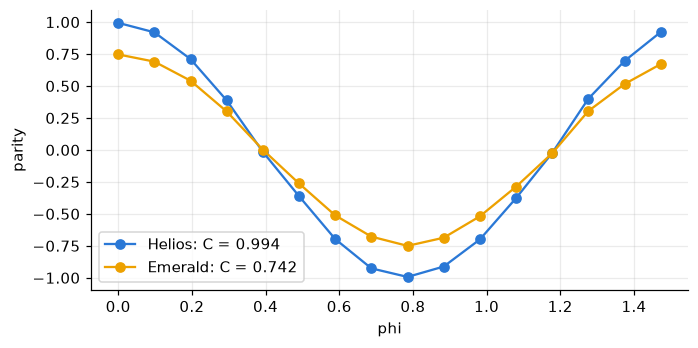

In [3]:
def parity_program(n, phi):
    return program(n, ["h q[0]", *(f"cx q[{i}],q[{i + 1}]" for i in range(n - 1)),
                       *(f"rz({phi}) q[{i}]" for i in range(n)), *(f"h q[{i}]" for i in range(n))])

def parity(counts):
    return sum(v * (-1) ** k.count("1") for k, v in counts.items()) / sum(counts.values())

def oscillation(backend, n, noise=True, points=16):
    phis = np.linspace(0, 2 * np.pi / n, points, endpoint=False)
    ps = np.array([parity(run(backend, parity_program(n, p), shots=8000, noise=noise, routing=True, seed=20 + i)["result"]["counts"])
                   for i, p in enumerate(phis)])
    A = np.column_stack([np.cos(n * phis), np.sin(n * phis)])       # fit C cos(n phi + delta)
    a, b = np.linalg.lstsq(A, ps, rcond=None)[0]
    return phis, ps, float(np.hypot(a, b))

fig, ax = plt.subplots(figsize=(7, 3.3))
for b in ("quantinuum_helios", "iqm_emerald"):
    phis, ps, C = oscillation(b, 4)
    ax.plot(phis, ps, "o-", color=COLORS[b], label=f"{NAMES[b]}: C = {C:.3f}")
ax.set_xlabel("phi"); ax.set_ylabel("parity"); ax.legend(); plt.show()

## 3. GHZ₄ fidelity on every twin

Populations and coherence together give the fidelity; every twin certifies genuine four-qubit entanglement (F > 0.5).

In [4]:
rows = []
for b in ALL_BACKENDS:
    P = populations(b, 4)
    C = oscillation(b, 4, points=8)[2]
    rows.append({"twin": NAMES[b], "populations": round(P, 4), "coherence C": round(C, 4),
                 "fidelity F": round(P / 2 + C / 2, 4), "entangled (F > 0.5)": P / 2 + C / 2 > 0.5})
pd.DataFrame(rows).set_index("twin")

,populations,coherence C,fidelity F,entangled (F > 0.5)
twin,,,,
Helios,0.9966,0.9860,0.9913,True
Forte,0.9680,0.9331,0.9506,True
Ankaa-3,0.8527,0.7116,0.7821,True
Emerald,0.8656,0.7358,0.8007,True
Heron r3,0.9848,0.9670,0.9759,True
Nighthawk,0.9563,0.9061,0.9312,True
Willow,0.9645,0.9306,0.9476,True


## 4. Fidelity against width

Fidelity falls with the number of qubits; where it crosses 0.5, the twin can no longer certify an n-qubit GHZ state.

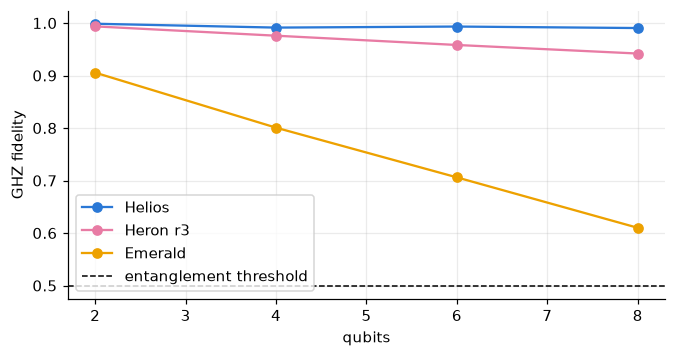

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for b in ("quantinuum_helios", "ibm_heron", "iqm_emerald"):
    ns = [2, 4, 6, 8]
    F = [populations(b, n) / 2 + oscillation(b, n, points=2 * n)[2] / 2 for n in ns]
    ax.plot(ns, F, "o-", color=COLORS[b], label=NAMES[b])
ax.axhline(0.5, color="black", ls="--", lw=1, label="entanglement threshold")
ax.set_xlabel("qubits"); ax.set_ylabel("GHZ fidelity"); ax.legend(); plt.show()

## Takeaways

- GHZ fidelity is certified the way experiments do it: populations plus parity-oscillation contrast.
- The twins predict at which width each device stops certifying genuine multipartite entanglement.